# 01 - Analyse exploratoire (EDA)
**Projet :** Student Mental Health Risk Prediction (projet éducatif, jury blanc)

**Objectif :** comprendre la structure réelle des données et leur qualité avant tout prétraitement.

**Règles :**
- `data/raw/` n'est jamais modifié.
- Aucune statistique de transformation (imputation, mise à l'échelle) n'est retenue depuis ce notebook : elles seront calculées sur le jeu d'entraînement uniquement (phase 2).
- Le dataset est **synthétique** et la cible est dérivée des variables : les associations observées reflètent la règle de génération, pas la réalité clinique.
- Ce travail n'est ni un outil de diagnostic ni un outil de dépistage.

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = Path("..") / "data" / "raw" / "student_mental_health.csv"
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Mental_Health_Risk"
TARGET_ORDER = ["Low", "Medium", "High"]
ID_COL = "Student_ID"
NUM_COLS = ["Age", "Year_of_Study", "Sleep_Hours", "Study_Hours_Per_Week", "GPA",
            "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress",
            "Family_Support", "Attendance_Rate"]
CAT_COLS = ["Gender", "Physical_Activity", "Part_Time_Job", "Diet_Quality",
            "Previous_Mental_Health_History"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 1. Chargement et structure

In [18]:
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
unexpected = set(df.columns) - set(NUM_COLS + CAT_COLS + [TARGET, ID_COL])
missing_cols = set(NUM_COLS + CAT_COLS + [TARGET, ID_COL]) - set(df.columns)
print("Colonnes inattendues :", unexpected, "| colonnes absentes :", missing_cols)
print()
print(df.dtypes)
df.head()

Dimensions : (2000, 17)
Colonnes inattendues : set() | colonnes absentes : set()

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. Qualité des données

### 2.1 Valeurs manquantes

In [19]:
na = df.isna().sum()
na_table = pd.DataFrame({"manquants": na, "pourcentage": (na / len(df) * 100).round(2)})
na_table = na_table[na_table["manquants"] > 0].sort_values("manquants", ascending=False)
print(na_table)
print("Lignes avec au moins un manquant :", int(df.isna().any(axis=1).sum()),
      f"({df.isna().any(axis=1).mean()*100:.1f} %)")
print("Manquants dans la cible :", int(df[TARGET].isna().sum()))

                    manquants  pourcentage
Financial_Stress           91         4.55
Diet_Quality               69         3.45
Sleep_Hours                62         3.10
Social_Media_Hours         58         2.90
Family_Support             54         2.70
Attendance_Rate            47         2.35
GPA                        38         1.90
Lignes avec au moins un manquant : 394 (19.7 %)
Manquants dans la cible : 0


### 2.2 Doublons et identifiant

In [20]:
print("Lignes dupliquées :", int(df.duplicated().sum()))
print("Doublons hors Student_ID :", int(df.drop(columns=[ID_COL]).duplicated().sum()))
print("Student_ID uniques :", df[ID_COL].nunique(), "sur", len(df))

Lignes dupliquées : 0
Doublons hors Student_ID : 0
Student_ID uniques : 2000 sur 2000


### 2.3 Valeurs hors plage attendue
Les plages viennent de la documentation du dataset (à vérifier, pas à croire).

In [21]:
expected = {
    "Age": (18, 30), "Year_of_Study": (1, 5), "Sleep_Hours": (3.5, 9.5),
    "Study_Hours_Per_Week": (5, 55), "GPA": (0, 4.0), "Social_Media_Hours": (0.5, 10.0),
    "Screen_Time_Hours": (1.0, 14.0), "Financial_Stress": (1, 10),
    "Family_Support": (1, 10), "Attendance_Rate": (0, 100),
}
rows = []
for col, (lo, hi) in expected.items():
    s = df[col].dropna()
    rows.append({"colonne": col, "min": s.min(), "max": s.max(),
                 "plage_attendue": f"{lo}-{hi}",
                 "sous_min": int((s < lo).sum()), "sur_max": int((s > hi).sum())})
pd.DataFrame(rows)

,colonne,min,max,plage_attendue,sous_min,sur_max
0,Age,17.0,29.00,18-30,93,0
1,Year_of_Study,1.0,5.00,1-5,0,0
2,Sleep_Hours,3.3,10.00,3.5-9.5,1,17
3,Study_Hours_Per_Week,2.4,38.30,5-55,6,0
4,GPA,1.5,3.66,0-4.0,0,0
5,Social_Media_Hours,2.1,10.00,0.5-10.0,0,0
6,Screen_Time_Hours,3.3,14.00,1.0-14.0,0,0
7,Financial_Stress,1.4,10.00,1-10,0,0
8,Family_Support,1.7,9.90,1-10,0,0
9,Attendance_Rate,54.4,100.00,0-100,0,0


### 2.4 Variables catégorielles : modalités exactes
`repr` révèle les espaces ou différences de casse.

In [22]:
for col in CAT_COLS + [TARGET]:
    print(col)
    print(df[col].map(repr).value_counts(dropna=False).to_string())
    print()

Gender
Gender
'Female'        971
'Male'          932
'Non-binary'     97

Physical_Activity
Physical_Activity
'Moderate'    906
'Low'         679
'High'        415

Part_Time_Job
Part_Time_Job
'No'     1289
'Yes'     711

Diet_Quality
Diet_Quality
'Average'    860
'Poor'       587
'Good'       484
nan           69

Previous_Mental_Health_History
Previous_Mental_Health_History
'No'     1408
'Yes'     592

Mental_Health_Risk
Mental_Health_Risk
'High'      680
'Medium'    660
'Low'       660



## 3. Variable cible

                    effectif  pourcentage
Mental_Health_Risk                       
Low                      660         33.0
Medium                   660         33.0
High                     680         34.0


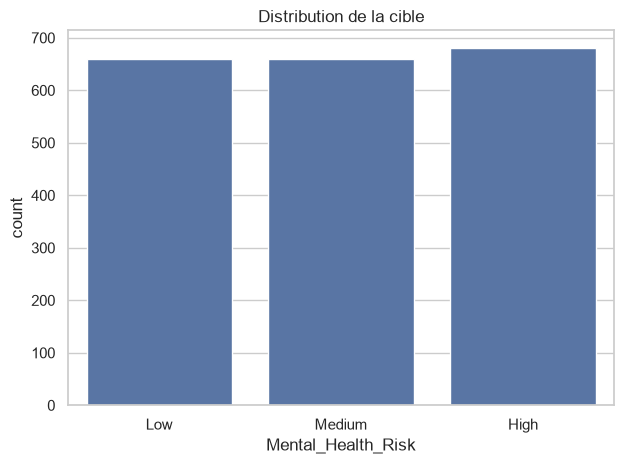

In [23]:
counts = df[TARGET].value_counts().reindex(TARGET_ORDER)
print(pd.DataFrame({"effectif": counts, "pourcentage": (counts / len(df) * 100).round(1)}))
ax = sns.countplot(data=df, x=TARGET, order=TARGET_ORDER)
ax.set_title("Distribution de la cible")
savefig("01_target_distribution")

## 4. Distributions univariées

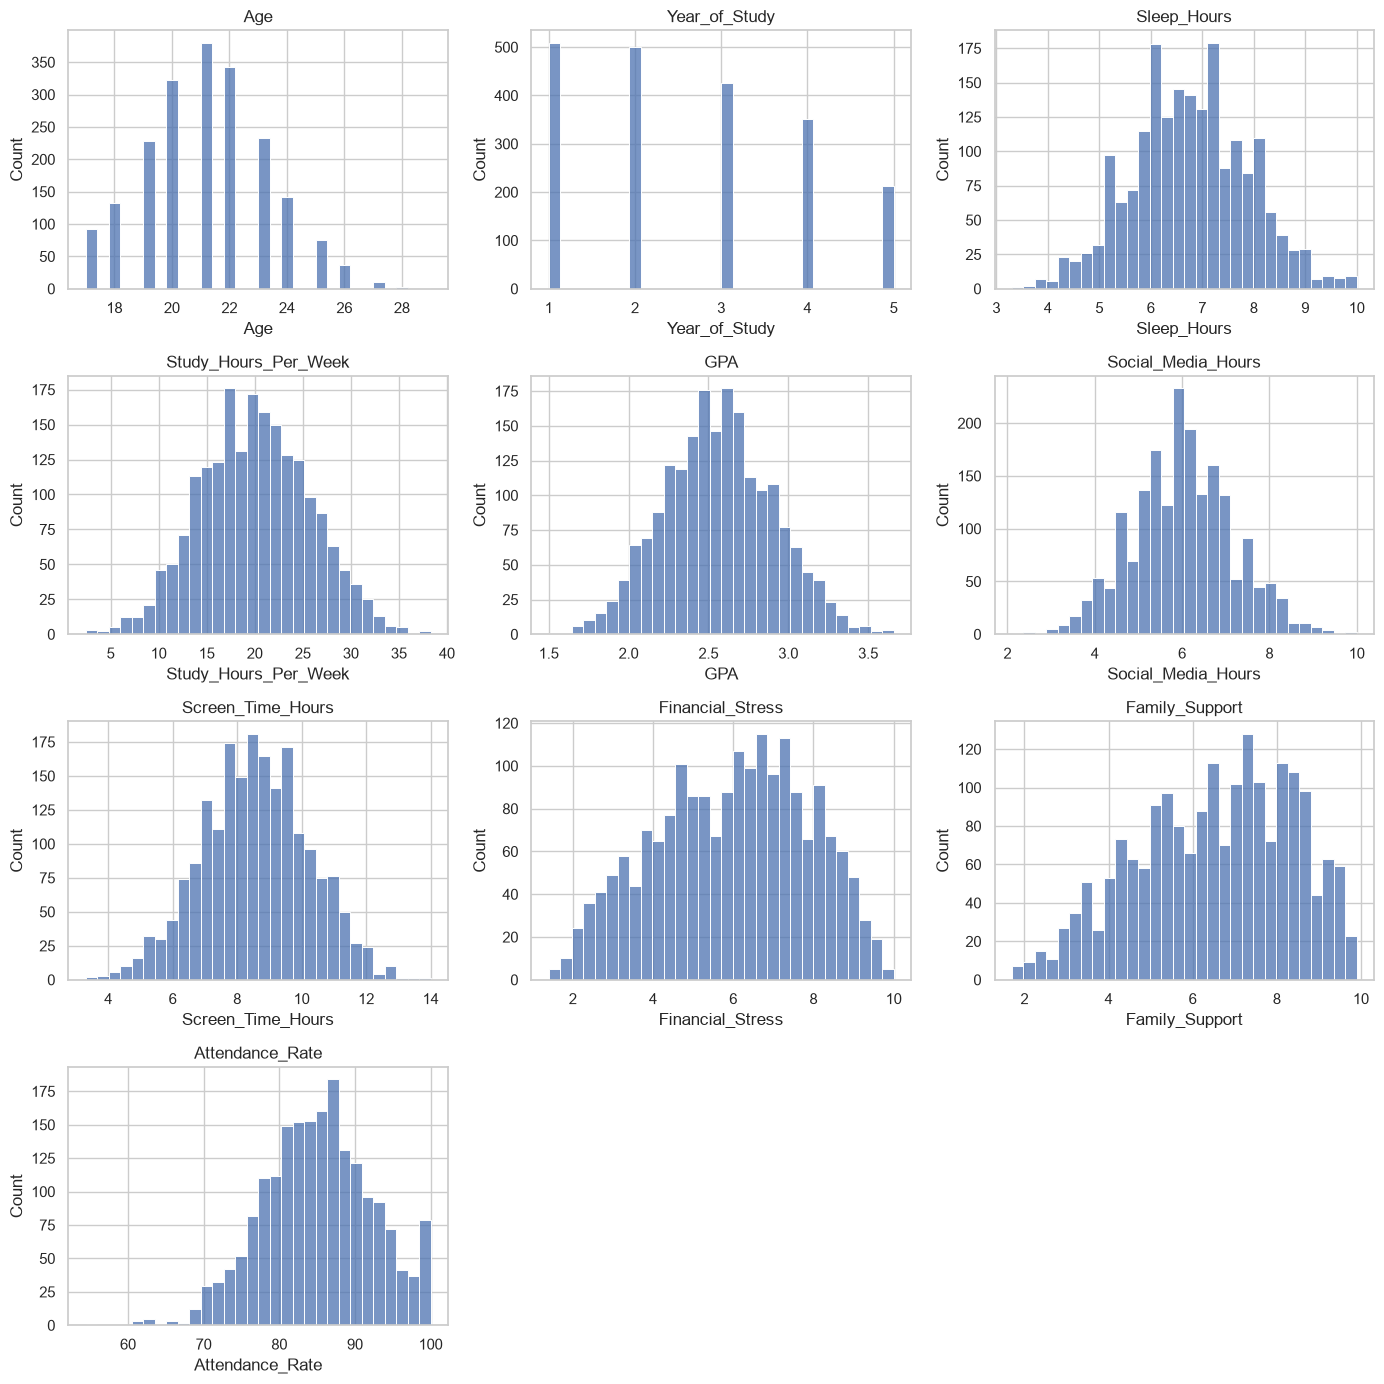

In [24]:
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df[col].dropna(), bins=30, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(NUM_COLS):]:
    ax.axis("off")
savefig("02_numeric_histograms")

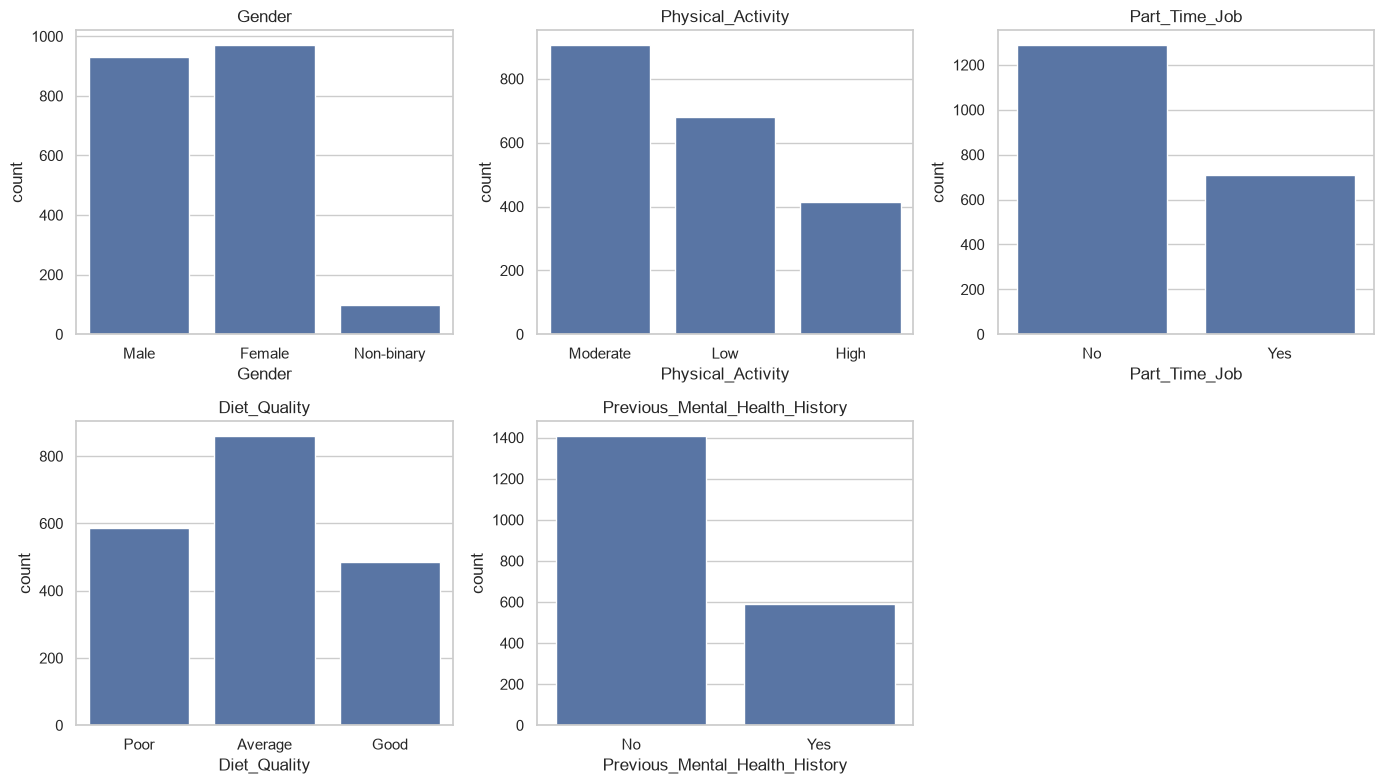

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), CAT_COLS):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(CAT_COLS):]:
    ax.axis("off")
savefig("03_categorical_counts")

### Valeurs atypiques (IQR) — description uniquement, rien n'est supprimé

In [26]:
rows = []
for col in NUM_COLS:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"colonne": col, "borne_basse": round(lo, 2), "borne_haute": round(hi, 2),
                 "n_hors_bornes": int(((s < lo) | (s > hi)).sum())})
pd.DataFrame(rows)

,colonne,borne_basse,borne_haute,n_hors_bornes
0,Age,15.50,27.50,4
1,Year_of_Study,-3.50,8.50,0
2,Sleep_Hours,3.60,10.00,2
3,Study_Hours_Per_Week,4.00,36.00,7
4,GPA,1.61,3.50,9
5,Social_Media_Hours,3.01,8.91,20
6,Screen_Time_Hours,3.95,13.15,7
7,Financial_Stress,0.15,11.75,0
8,Family_Support,0.75,12.35,0
9,Attendance_Rate,65.75,104.55,12


In [27]:
print(df[NUM_COLS].describe().T.round(2))

                       count   mean   std   min    25%    50%    75%     max
Age                   2000.0  21.13  2.14  17.0  20.00  21.00  23.00   29.00
Year_of_Study         2000.0   2.63  1.32   1.0   1.00   2.00   4.00    5.00
Sleep_Hours           1938.0   6.76  1.13   3.3   6.00   6.70   7.60   10.00
Study_Hours_Per_Week  2000.0  20.00  5.72   2.4  16.00  19.80  24.00   38.30
GPA                   1962.0   2.56  0.34   1.5   2.32   2.56   2.79    3.66
Social_Media_Hours    1942.0   6.01  1.15   2.1   5.22   6.00   6.70   10.00
Screen_Time_Hours     2000.0   8.55  1.66   3.3   7.40   8.50   9.70   14.00
Financial_Stress      1909.0   5.96  1.89   1.4   4.50   6.10   7.40   10.00
Family_Support        1946.0   6.52  1.84   1.7   5.10   6.70   8.00    9.90
Attendance_Rate       1953.0  85.08  7.22  54.4  80.30  85.10  90.00  100.00


## 5. Relation entre les variables et la cible
Association observée dans ce dataset, **pas** de causalité.

In [28]:
print(df.groupby(TARGET)[NUM_COLS].mean().reindex(TARGET_ORDER).T.round(2))

Mental_Health_Risk      Low  Medium   High
Age                   21.11   21.14  21.14
Year_of_Study          2.90    2.64   2.36
Sleep_Hours            7.52    6.73   6.04
Study_Hours_Per_Week  21.70   19.98  18.36
GPA                    2.72    2.55   2.42
Social_Media_Hours     5.76    5.92   6.35
Screen_Time_Hours      8.26    8.42   8.96
Financial_Stress       5.24    5.90   6.69
Family_Support         7.09    6.53   5.96
Attendance_Rate       86.33   85.19  83.77


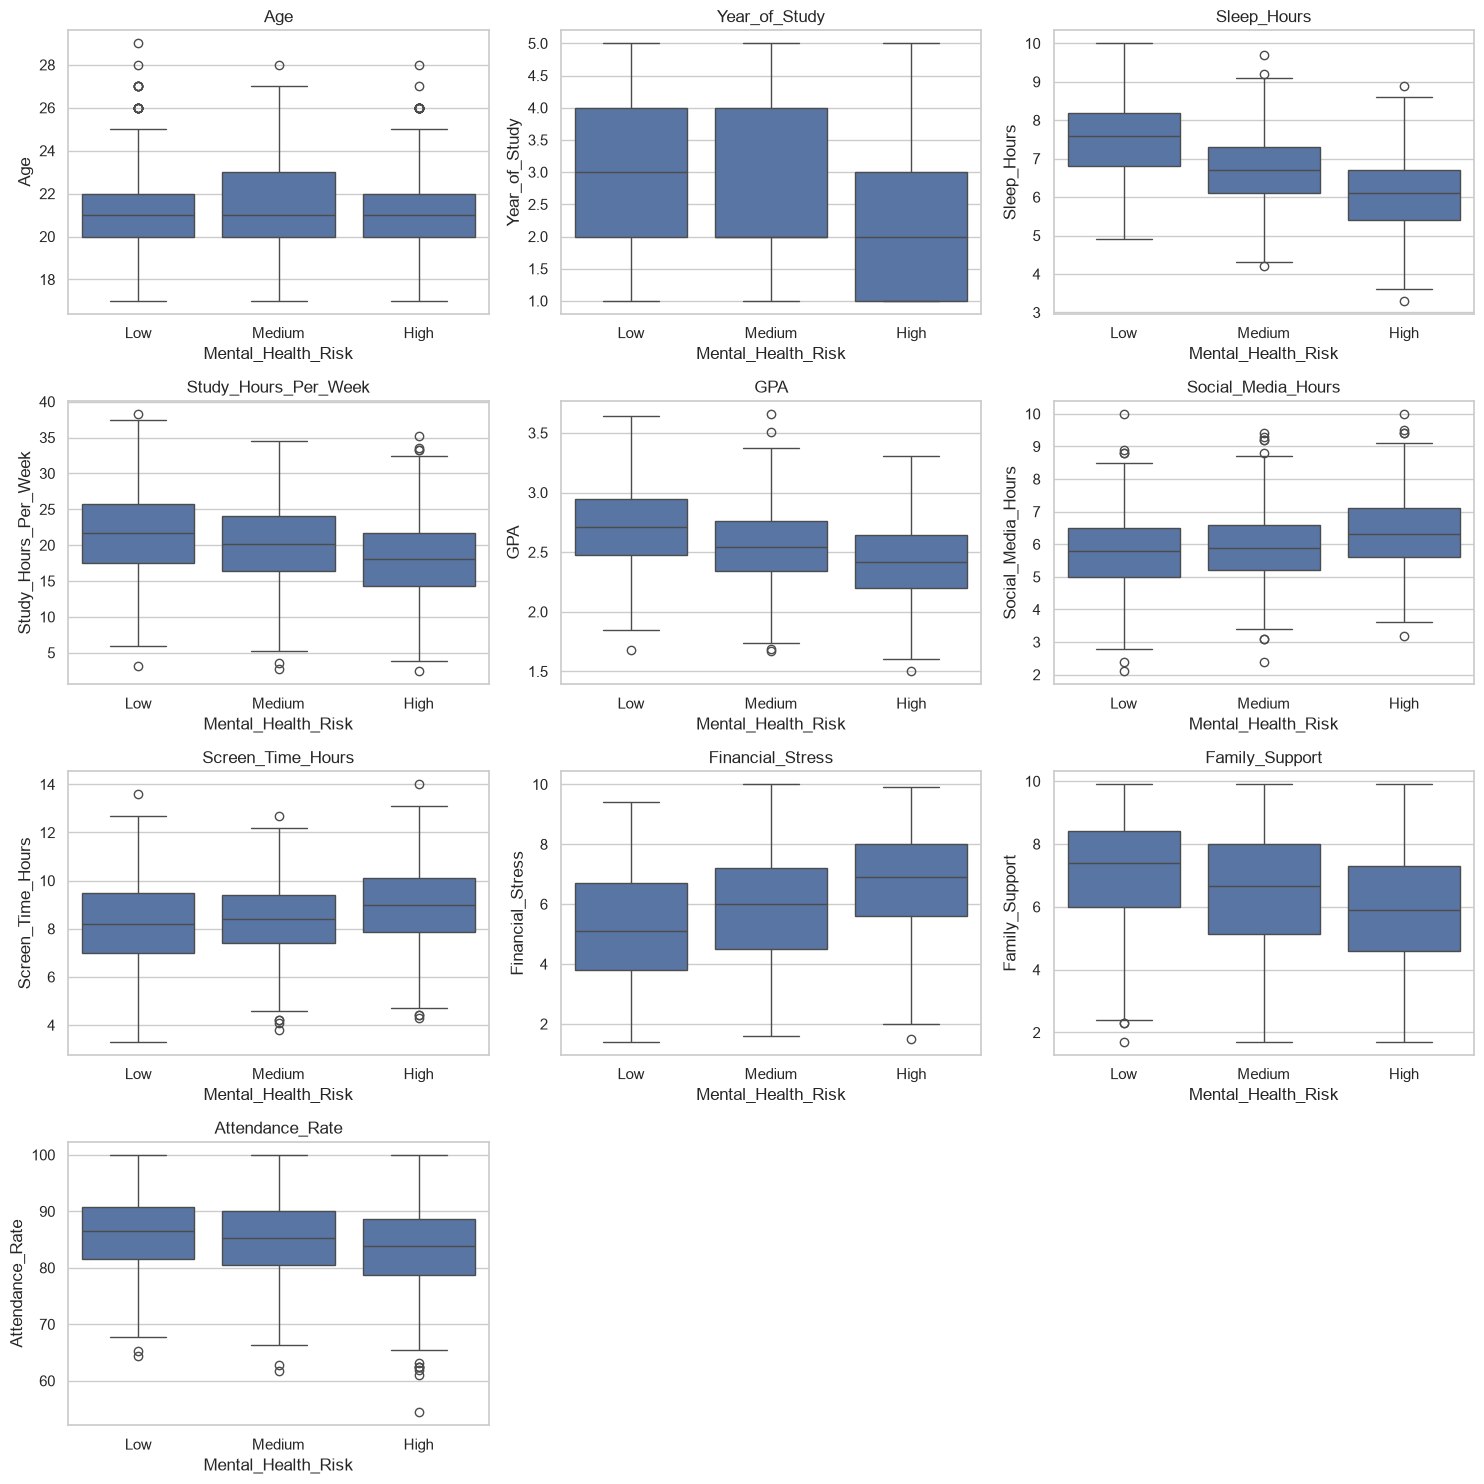

In [29]:
fig, axes = plt.subplots(4, 3, figsize=(15, 15))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, order=TARGET_ORDER, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(NUM_COLS):]:
    ax.axis("off")
savefig("04_numeric_vs_target")

In [30]:
for col in CAT_COLS:
    tab = pd.crosstab(df[col].fillna("(manquant)"), df[TARGET], normalize="index")[TARGET_ORDER]
    print(col, "(proportion de chaque classe par modalité)")
    print((tab * 100).round(1))
    print()

Gender (proportion de chaque classe par modalité)
Mental_Health_Risk   Low  Medium  High
Gender                                
Female              33.5    31.9  34.6
Male                31.8    34.9  33.4
Non-binary          40.2    25.8  34.0

Physical_Activity (proportion de chaque classe par modalité)
Mental_Health_Risk   Low  Medium  High
Physical_Activity                     
High                49.4    30.4  20.2
Low                 22.8    31.2  45.9
Moderate            33.1    35.5  31.3

Part_Time_Job (proportion de chaque classe par modalité)
Mental_Health_Risk   Low  Medium  High
Part_Time_Job                         
No                  36.2    33.5  30.3
Yes                 27.1    32.1  40.8

Diet_Quality (proportion de chaque classe par modalité)
Mental_Health_Risk   Low  Medium  High
Diet_Quality                          
(manquant)          34.8    34.8  30.4
Average             33.5    34.2  32.3
Good                42.8    29.8  27.5
Poor                24.0    33.7

## 6. Corrélations
La cible est encodée en ordre Low < Medium < High **uniquement pour cette exploration** (Spearman).

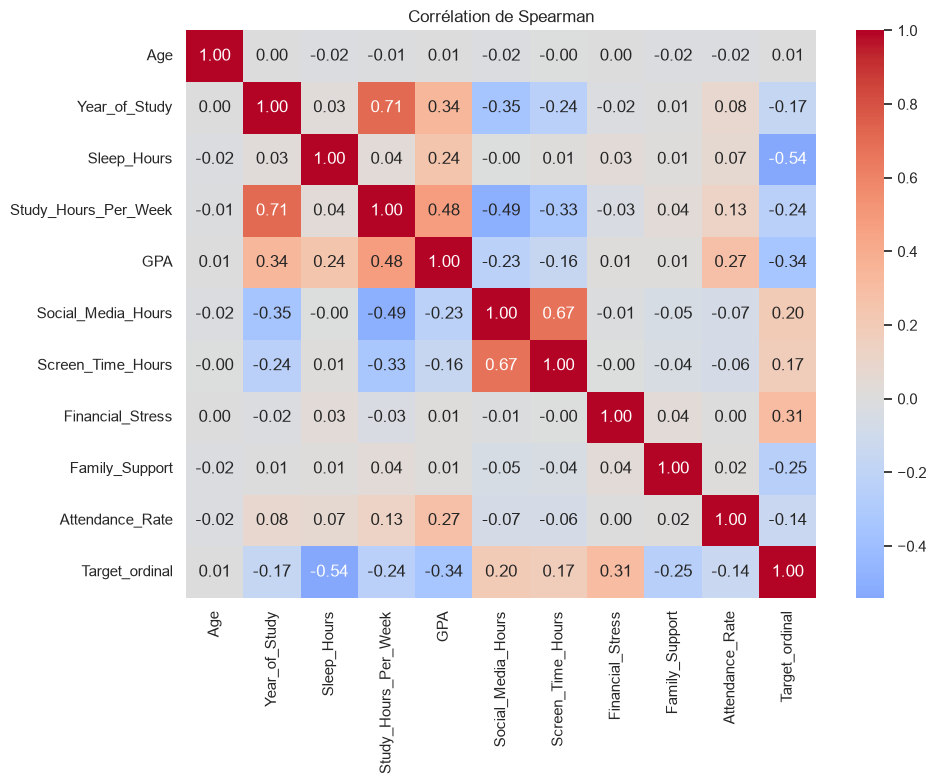

Sleep_Hours            -0.541
GPA                    -0.344
Family_Support         -0.250
Study_Hours_Per_Week   -0.240
Year_of_Study          -0.166
Attendance_Rate        -0.142
Age                     0.005
Screen_Time_Hours       0.173
Social_Media_Hours      0.198
Financial_Stress        0.311
Name: Target_ordinal, dtype: float64


In [31]:
tmp = df[NUM_COLS].copy()
tmp["Target_ordinal"] = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})
corr = tmp.corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation de Spearman")
savefig("05_correlation_heatmap")
print(corr["Target_ordinal"].drop("Target_ordinal").sort_values().round(3))

## 7. Les valeurs manquantes dépendent-elles de la cible ?
Si oui, l'absence d'information serait elle-même informative.

In [32]:
rows = []
for col in na_table.index:
    miss_rate = df.groupby(TARGET)[col].apply(lambda s: s.isna().mean() * 100).reindex(TARGET_ORDER)
    rows.append(miss_rate.rename(col))
print(pd.DataFrame(rows).round(2))

Mental_Health_Risk   Low  Medium  High
Financial_Stress    5.15    5.61  2.94
Diet_Quality        3.64    3.64  3.09
Sleep_Hours         1.97    4.09  3.24
Social_Media_Hours  2.73    3.33  2.65
Family_Support      3.03    2.12  2.94
Attendance_Rate     2.88    2.12  2.06
GPA                 1.97    1.82  1.91


### 7.bis Test de l'hypothèse de *clipping*
Le *clipping* consiste à ramener toute valeur hors limites à la limite elle-même. Si le générateur l'a fait, de nombreuses lignes auront exactement la valeur maximale (ou minimale). On compte donc les lignes égales au maximum observé.

In [33]:
rows = []
for col in NUM_COLS:
    s = df[col].dropna()
    rows.append({"colonne": col, "min": s.min(), "n_egal_min": int((s == s.min()).sum()),
                 "max": s.max(), "n_egal_max": int((s == s.max()).sum()),
                 "pct_egal_max": round((s == s.max()).mean() * 100, 2)})
pd.DataFrame(rows)

,colonne,min,n_egal_min,max,n_egal_max,pct_egal_max
0,Age,17.0,93,29.00,1,0.05
1,Year_of_Study,1.0,509,5.00,213,10.65
2,Sleep_Hours,3.3,1,10.00,5,0.26
3,Study_Hours_Per_Week,2.4,1,38.30,1,0.05
4,GPA,1.5,1,3.66,1,0.05
5,Social_Media_Hours,2.1,1,10.00,2,0.10
6,Screen_Time_Hours,3.3,1,14.00,1,0.05
7,Financial_Stress,1.4,1,10.00,1,0.05
8,Family_Support,1.7,4,9.90,9,0.46
9,Attendance_Rate,54.4,1,100.00,53,2.71


## 8. Synthèse

**Vérifié dans ce notebook**
- 2000 lignes, 17 colonnes, aucun doublon, `Student_ID` unique (identifiant à exclure des variables explicatives).
- Cible quasi équilibrée : Low 33 %, Medium 33 %, High 34 %. Le rééquilibrage (SMOTE) n'est pas justifié à ce stade.
- Valeurs manquantes dans 7 variables (1,9 % à 4,55 %) ; 19,7 % des lignes ont au moins un manquant. Aucune dans la cible.
- Quelques valeurs hors plage documentée (Age < 18, Sleep_Hours > 9,5, Study_Hours < 5) ; les valeurs atypiques IQR restent plausibles et sont conservées.
- Variables les plus associées à la cible (Spearman) : Sleep_Hours (-0,54), GPA (-0,34), Financial_Stress (+0,31), Family_Support (-0,25), Study_Hours (-0,24). Age : aucune association.
- Catégorielles : Previous_Mental_Health_History, Physical_Activity, Diet_Quality et Part_Time_Job sont associées à la cible ; Gender très peu (Non-binary : 97 lignes seulement, proportions instables).

**Limites et mises en garde**
- Dataset synthétique : la cible est dérivée des variables. Les associations reflètent la règle de génération, pas la réalité ; de bonnes performances futures ne prouvent rien sur des étudiants réels.
- Association n'est pas causalité.
- Les différences de taux de manquants selon la cible portent sur de petits effectifs ; aucun test statistique n'a été fait, on ne conclut pas.
- Hypothèse de clipping : voir le tableau ci-dessus.
- Projet éducatif : ni diagnostic, ni dépistage, ni décision disciplinaire.

**Décisions provisoires pour la phase 2 (à valider)**
- Séparation 80/20 stratifiée avant tout prétraitement.
- Imputation médiane (numériques) / mode (catégorielles) dans un Pipeline, ajustée sur le train seulement.
- Encodage ordinal (Physical_Activity, Diet_Quality), one-hot (Gender), binaire (Part_Time_Job, Previous_Mental_Health_History).
- Valeurs atypiques conservées ; mise à l'échelle seulement pour la régression logistique.
- Pas de SMOTE ; `StratifiedKFold` et métriques F1 / matrice de confusion.